In [1]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm
import h5py

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

import sys
sys.path.append("..") 

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [2]:
from processing import  load_UCI_dataset, plot_regression_results, print_metrics, plot_convtran_loss
from UCI.pre_processing import  create_dataloaders

In [3]:
BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/8sec_50%overlap/vitaldb_checkpoints"
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(WINDOW_SIZE= 1000, STEP_SIZE= 500)

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [05:16<00:00, 30.32it/s]


Skipped recordings: 103


100%|██████████| 1200/1200 [00:27<00:00, 43.58it/s]


Skipped recordings: 8


100%|██████████| 1200/1200 [00:25<00:00, 46.41it/s]


Skipped recordings: 9


In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# The shape should be : (batch, channels, length), length = 8*125 = 1000samples, only one channel as PPG and 

X_train: (517037, 1, 1000)
y_train: (517037, 2)
X_val: (65284, 1, 1000)
y_val: (65284, 2)
X_test: (65554, 1, 1000)
y_test: (65554, 2)


In [5]:
print(X_train.dtype)
print(y_train.dtype)


float32
float32


In [6]:
cat ConvTran/Models/model.py

import numpy as np
from torch import nn
from Models.AbsolutePositionalEncoding import tAPE, AbsolutePositionalEncoding, LearnablePositionalEncoding
from Models.Attention import Attention, Attention_Rel_Scl, Attention_Rel_Vec


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class Permute(nn.Module):
    def forward(self, x):
        return x.permute(1, 0, 2)


def model_factory(config):
    if config['Net_Type'][0] == 'T':
        model = Transformer(config, output_size=config['output_size'])
    elif config['Net_Type'][0] == 'CC-T':
        model = CasualConvTran(config, output_size=config['output_size'])
    else:
        model = ConvTran(config, output_size=config['output_size'])
    return model


class Transformer(nn.Module):
    def __init__(self, config, output_size):
        super().__init__()
        # Parameters Initialization -----------------------------------------------
        channel_size, seq_len = config['Data_sh

In [16]:
train_loader, val_loader, test_loader = create_dataloaders(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    batch_size=64
)

X_batch, y_batch = next(iter(train_loader))

print("X:", X_batch.shape, X_batch.dtype)
print("y:", y_batch.shape, y_batch.dtype)

X: torch.Size([64, 1, 1000]) torch.float32
y: torch.Size([64, 2]) torch.float32


In [17]:
config = {
    # Input
    'Data_shape': (32, 1, 1000),

    # ConvTran architecture
    'emb_size': 16,
    'num_heads': 8,
    'dim_ff': 256,

    # Positional encoding
    'Fix_pos_encode': 'tAPE',
    'Rel_pos_encode': 'eRPE',

    # Dropout
    'dropout': 0.01,

    # Regression
    'output_size': 2,

    # Model type
    'Net_Type': ['C-T'],
}

In [18]:
import sys

sys.path.insert(
    0,
    "/data1/yashvi_bhuva/BP_estimation_using_PPG/ConvTran/ConvTran"
)
from Models.model import model_factory
model = model_factory(config)

X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("Input :", X_batch.shape)
print("Output:", output.shape)

Input : torch.Size([64, 1, 1000])
Output: torch.Size([64, 2])


In [19]:
import torch.nn as nn

criterion = nn.SmoothL1Loss()

loss = criterion(output, y_batch)

print("Prediction shape:", output.shape)
print("Target shape:", y_batch.shape)
print("Loss:", loss.item())

loss.backward()

print("Backward pass successful")

Prediction shape: torch.Size([64, 2])
Target shape: torch.Size([64, 2])
Loss: 95.56980895996094
Backward pass successful


In [20]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

optimizer.step()

print("Optimizer step successful")

Optimizer step successful


In [21]:
model.train()

X_batch, y_batch = next(iter(train_loader))

optimizer.zero_grad()

pred = model(X_batch)

loss = criterion(pred, y_batch)

loss.backward()

optimizer.step()

print("Loss:", loss.item())
print("Training step successful")

Loss: 98.63871765136719
Training step successful


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_factory(config).to(device)

In [23]:
loss_module = torch.nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [24]:
"""
Latency benchmark for PyTorch models (batch size 1, the realistic wearable case).
 
What it does right (compared with a single time.time() around model(x)):
  * model.eval() + torch.no_grad()      -> no dropout, no autograd overhead
  * warm-up runs                        -> excludes one-time CUDA/cuDNN setup
  * torch.cuda.synchronize() on GPU     -> GPU kernels are asynchronous, so without
                                           this you time only the kernel *launch*
  * many runs, median / p95 / std       -> one run is noise
  * real samples from your data         -> not a single cached input
  * input shape printed                 -> catches models that silently pad/resample
  * preprocessing timed separately      -> shows where the time actually goes
 
Basic use (notebook or script):
 
    from benchmark_latency import benchmark_model, print_table
 
    results = {}
    results["8s"] = benchmark_model(model_8s, X_train_8s)
    results["5s"] = benchmark_model(model_5s, X_train_5s)
    results["3s"] = benchmark_model(model_3s, X_train_3s)
    print_table(results)
 
    # Rough proxy for a weak device: CPU, one thread
    cpu = {k: benchmark_model(m, X, device="cpu", num_threads=1)
           for k, (m, X) in {"8s": (model_8s, X_train_8s), ...}.items()}
    print_table(cpu)
 
X_train can be a numpy array or torch tensor shaped (N, ...) exactly as the model
expects for a batch, e.g. (N, 1, T) or (N, T). Each timed call uses X[i:i+1].
"""
import time
 
import numpy as np
import torch
 
 
# --------------------------------------------------------------------------- #
# helpers
# --------------------------------------------------------------------------- #
def _is_cuda(device):
    return str(device).startswith("cuda")
 
 
def _sync(device):
    if _is_cuda(device):
        torch.cuda.synchronize()
 
 
def _stats(times_s):
    ms = np.asarray(times_s, dtype=np.float64) * 1000.0
    return {
        "median_ms": float(np.median(ms)),
        "mean_ms": float(ms.mean()),
        "std_ms": float(ms.std()),
        "p95_ms": float(np.percentile(ms, 95)),
        "min_ms": float(ms.min()),
        "n_runs": int(len(ms)),
    }
 
 
def time_callable(fn, inputs, device="cpu", n_warmup=30, n_runs=300):
    """
    Time fn(x) where x cycles through the list `inputs`.
    Use device="cuda" when fn launches GPU work so we synchronize correctly.
    Returns a dict of statistics in milliseconds.
    """
    for i in range(n_warmup):
        fn(inputs[i % len(inputs)])
    _sync(device)
 
    times = []
    for i in range(n_runs):
        x = inputs[i % len(inputs)]
        _sync(device)                      # nothing left over from the previous run
        t0 = time.perf_counter()
        fn(x)
        _sync(device)                      # wait until the GPU has finished
        times.append(time.perf_counter() - t0)
    return _stats(times)
 
 
def _model_size(model):
    params = sum(p.numel() for p in model.parameters())
    nbytes = sum(p.numel() * p.element_size() for p in model.parameters())
    nbytes += sum(b.numel() * b.element_size() for b in model.buffers())
    return params, nbytes / 1024 ** 2
 
 
def _to_float_tensor(X):
    if not torch.is_tensor(X):
        X = torch.as_tensor(np.asarray(X))
    return X.float()
 
 
# --------------------------------------------------------------------------- #
# model-only benchmark
# --------------------------------------------------------------------------- #
def benchmark_model(model, X, device=None, n_warmup=30, n_runs=300,
                    n_samples=100, num_threads=None):
    """
    Model-only latency at batch size 1.
 
    device      : "cuda", "cpu", or None (cuda if available).
    num_threads : set e.g. 1 for a CPU single-thread proxy of a weak device.
    n_samples   : how many distinct real samples to cycle through.
    """
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
 
    prev_threads = torch.get_num_threads()
    if num_threads is not None:
        torch.set_num_threads(num_threads)
 
    try:
        model = model.to(device).eval()               # eval() is essential
        X = _to_float_tensor(X)
        idx = np.linspace(0, len(X) - 1, num=min(n_samples, len(X))).astype(int)
        inputs = [X[i:i + 1].to(device) for i in idx]
 
        @torch.no_grad()
        def run(x):
            return model(x)
 
        if _is_cuda(device):
            torch.cuda.reset_peak_memory_stats()
 
        out = time_callable(run, inputs, device, n_warmup, n_runs)
 
        params, size_mb = _model_size(model)
        out.update({
            "device": str(device),
            "threads": torch.get_num_threads() if not _is_cuda(device) else None,
            "input_shape": tuple(inputs[0].shape),
            "params_M": params / 1e6,
            "size_MB": size_mb,
            "peak_cuda_MB": (torch.cuda.max_memory_allocated() / 1024 ** 2
                             if _is_cuda(device) else None),
        })
        return out
    finally:
        torch.set_num_threads(prev_threads)
 
 
# --------------------------------------------------------------------------- #
# preprocessing and end-to-end
# --------------------------------------------------------------------------- #
def benchmark_preprocessing(preprocess_fn, raw_samples, n_warmup=30, n_runs=300):
    """
    Time your preprocessing (filtering, wavelet, FFT, feature extraction...) alone.
    preprocess_fn(raw) -> array/tensor ready for the model.
    raw_samples        : list of raw signals (one per call).
    """
    return time_callable(preprocess_fn, raw_samples, device="cpu",
                         n_warmup=n_warmup, n_runs=n_runs)
 
 
def benchmark_pipeline(model, preprocess_fn, raw_samples, device=None,
                       n_warmup=30, n_runs=300, num_threads=None):
    """
    End-to-end per-window latency: preprocess + host->device copy + model.
    The input shape produced by preprocess_fn must be what the model expects
    for batch size 1 (include the batch dimension).
    """
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
 
    prev_threads = torch.get_num_threads()
    if num_threads is not None:
        torch.set_num_threads(num_threads)
    try:
        model = model.to(device).eval()
 
        @torch.no_grad()
        def pipeline(raw):
            x = _to_float_tensor(preprocess_fn(raw)).to(device)
            return model(x)
 
        return time_callable(pipeline, raw_samples, device, n_warmup, n_runs)
    finally:
        torch.set_num_threads(prev_threads)
 
 
# --------------------------------------------------------------------------- #
# reporting
# --------------------------------------------------------------------------- #
def print_table(results):
    """results: {name: dict returned by benchmark_model}"""
    head = (f"{'name':<10}{'device':<8}{'thr':>4}  {'input shape':<20}"
            f"{'median ms':>10}{'p95 ms':>9}{'std ms':>8}"
            f"{'params M':>10}{'size MB':>9}{'peak GPU MB':>13}")
    print(head)
    print("-" * len(head))
    for name, r in results.items():
        thr = "-" if r.get("threads") is None else str(r["threads"])
        peak = "-" if r.get("peak_cuda_MB") is None else f"{r['peak_cuda_MB']:.0f}"
        print(f"{name:<10}{r['device']:<8}{thr:>4}  {str(r['input_shape']):<20}"
              f"{r['median_ms']:>10.2f}{r['p95_ms']:>9.2f}{r['std_ms']:>8.2f}"
              f"{r['params_M']:>10.2f}{r['size_MB']:>9.1f}{peak:>13}")


results = {
    "8s": benchmark_model(model, X_train),
    
}
print_table(results)

name      device   thr  input shape          median ms   p95 ms  std ms  params M  size MB  peak GPU MB
-------------------------------------------------------------------------------------------------------
8s        cuda       -  (1, 1, 1000)              4.88     6.12    1.15      0.03      7.8          140


In [25]:
import time
import numpy as np
import torch

def measure_inference_time(model, x, warmup=50, runs=500):
    model.eval()
    device = next(model.parameters()).device
    x = x.to(device)

    with torch.inference_mode():
        for _ in range(warmup):
            _ = model(x)

        if device.type == "cuda":
            torch.cuda.synchronize()

        times = []

        for _ in range(runs):
            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            with torch.inference_mode():
                _ = model(x)

            if device.type == "cuda":
                torch.cuda.synchronize()

            times.append((time.perf_counter() - start) * 1000)

    return {
        "mean_ms": np.mean(times),
        "median_ms": np.median(times),
        "p95_ms": np.percentile(times, 95),
    }
x = torch.tensor(X_train[:1], dtype=torch.float32)
x = x.to(device)
results = measure_inference_time(model, x)  # Measure inference time on a single sample

print(f"Mean latency:   {results['mean_ms']:.3f} ms")
print(f"Median latency: {results['median_ms']:.3f} ms")
print(f"P95 latency:    {results['p95_ms']:.3f} ms")

Mean latency:   4.564 ms
Median latency: 4.578 ms
P95 latency:    6.075 ms


In [26]:
from Training import SupervisedTrainer, validate, train_runner
trainer = SupervisedTrainer(
    model=model,
    dataloader=train_loader,
    device=device,
    loss_module=loss_module,
    optimizer=optimizer,
    l2_reg=None
)

val_evaluator = SupervisedTrainer(
    model=model,
    dataloader=val_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None
)

In [27]:
import os

config['optimizer'] = optimizer
config['loss_module'] = loss_module
config['patience'] = 5
config['key_metric'] = 'loss'
config['save_dir'] = './checkpoints'

os.makedirs(config['save_dir'], exist_ok=True)

In [28]:
config['epochs'] = 50

history = train_runner(
    config=config,
    model=model,
    trainer=trainer,
    val_evaluator=val_evaluator,
    path='./checkpoints/best_model.pth'
)

Training Epoch:   0%|          | 0/50 [00:00<?, ?it/s]2026-10-22 00:23:53,521 | INFO : Validation Summary: epoch: 1.000000 | loss: 56.345486 | SBP_MAE: 90.010422 | DBP_MAE: 23.680557 | SBP_RMSE: 92.782845 | DBP_RMSE: 26.145214 | 



Best validation loss: 56.3454859174793
Saving best model for epoch: 1



2026-10-22 00:23:53,808 | INFO : Epoch 1 Training Summary: epoch: 1.000000 | loss: 79.498740 | SBP_MAE: 112.967461 | DBP_MAE: 47.030006 | SBP_RMSE: 115.651772 | DBP_RMSE: 49.776104 | 
Training Epoch:   2%|▏         | 1/50 [16:40<13:37:28, 1001.00s/it]2026-10-22 00:38:56,927 | INFO : Validation Summary: epoch: 2.000000 | loss: 13.713000 | SBP_MAE: 20.081892 | DBP_MAE: 8.326846 | SBP_RMSE: 25.846758 | DBP_RMSE: 11.075572 | 
2026-10-22 00:38:57,068 | INFO : Epoch 2 Training Summary: epoch: 2.000000 | loss: 31.252225 | SBP_MAE: 53.570293 | DBP_MAE: 9.921356 | SBP_RMSE: 61.611629 | DBP_RMSE: 13.407681 | 
Training Epoch:   4%|▍         | 2/50 [31:44<12:34:48, 943.50s/it] 


Best validation loss: 13.713000187985738
Saving best model for epoch: 2



2026-10-22 00:54:00,578 | INFO : Validation Summary: epoch: 3.000000 | loss: 11.270346 | SBP_MAE: 15.808014 | DBP_MAE: 7.708102 | SBP_RMSE: 20.306389 | DBP_RMSE: 10.600677 | 
2026-10-22 00:54:00,734 | INFO : Epoch 3 Training Summary: epoch: 3.000000 | loss: 11.737775 | SBP_MAE: 16.779579 | DBP_MAE: 7.673827 | SBP_RMSE: 21.483839 | DBP_RMSE: 10.524886 | 
Training Epoch:   6%|▌         | 3/50 [46:47<12:04:49, 925.31s/it]

...

2026-10-22 07:43:47,860 | INFO : Validation Summary: epoch: 30.000000 | loss: 9.340503 | SBP_MAE: 13.206847 | DBP_MAE: 6.443730 | SBP_RMSE: 17.543249 | DBP_RMSE: 9.020883 | 
2026-10-22 07:43:47,865 | INFO : Epoch 30 Training Summary: epoch: 30.000000 | loss: 8.391045 | SBP_MAE: 11.748130 | DBP_MAE: 5.999135 | SBP_RMSE: 16.132778 | DBP_RMSE: 8.779366 | 
Training Epoch:  60%|██████    | 30/50 [7:36:35<5:02:38, 907.94s/it]

2026-10-22 07:58:54,970 | INFO : Validation Summary: epoch: 31.000000 | loss: 9.359481 | SBP_MAE: 13.253304 | DBP_MAE: 6.435784 | SBP_RMSE: 17.626791 | DBP_RMSE: 9.010108 | 
2026-10-22 07:58:54,999 | INFO : Epoch 31 Training Summary: epoch: 31.000000 | loss: 8.361814 | SBP_MAE: 11.702256 | DBP_MAE: 5.986606 | SBP_RMSE: 16.078445 | DBP_RMSE: 8.765347 | 
Training Epoch:  62%|██████▏   | 31/50 [7:51:42<4:47:26, 907.70s/it]

2026-10-22 08:14:02,082 | INFO : Validation Summary: epoch: 32.000000 | loss: 9.445886 | SBP_MAE: 13.349724 | DBP_MAE: 6.512058 | SBP_RMSE: 17.773359 | DBP_RMSE: 9.141106 | 
2026-10-22 08:14:02,092 | INFO : Epoch 32 Training Summary: epoch: 32.000000 | loss: 8.331959 | SBP_MAE: 11.658452 | DBP_MAE: 5.970273 | SBP_RMSE: 16.045341 | DBP_RMSE: 8.750487 | 
Training Epoch:  64%|██████▍   | 32/50 [8:06:49<4:32:15, 907.52s/it]

2026-10-22 08:29:09,399 | INFO : Validation Summary: epoch: 33.000000 | loss: 9.435558 | SBP_MAE: 13.297173 | DBP_MAE: 6.544549 | SBP_RMSE: 17.708796 | DBP_RMSE: 9.167877 | 
2026-10-22 08:29:09,409 | INFO : Epoch 33 Training Summary: epoch: 33.000000 | loss: 8.300320 | SBP_MAE: 11.610544 | DBP_MAE: 5.954670 | SBP_RMSE: 15.987121 | DBP_RMSE: 8.734076 | 
Training Epoch:  66%|██████▌   | 33/50 [8:21:56<4:17:06, 907.46s/it]

2026-10-22 08:44:16,465 | INFO : Validation Summary: epoch: 34.000000 | loss: 9.699772 | SBP_MAE: 13.727544 | DBP_MAE: 6.643385 | SBP_RMSE: 18.021158 | DBP_RMSE: 9.118206 | 
2026-10-22 08:44:16,475 | INFO : Epoch 34 Training Summary: epoch: 34.000000 | loss: 8.268080 | SBP_MAE: 11.566328 | DBP_MAE: 5.934328 | SBP_RMSE: 15.942504 | DBP_RMSE: 8.713675 | 
2026-10-22 08:44:16,476 | INFO : Early stopping at epoch 34. Best validation loss: 9.291738
2026-10-22 08:44:16,477 | INFO : Train Time: 8.0 hours, 37.0 minutes, 3.702662467956543 seconds



The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


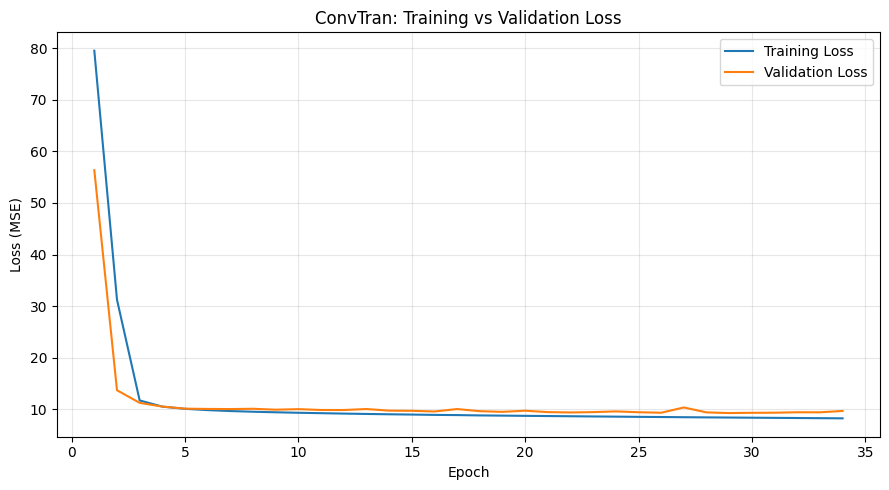

In [29]:
plot_convtran_loss(history)

In [30]:
checkpoint = torch.load(
    './checkpoints/model_best.pth',
    map_location=device
)

model.load_state_dict(checkpoint['state_dict'])
model.to(device)

test_evaluator = SupervisedTrainer(
    model=model,
    dataloader=test_loader,
    device=device,
    loss_module=loss_module,
    optimizer=None,
    l2_reg=None,
    print_interval=10,
    console=True,
    print_conf_mat=False
)

In [31]:
test_metrics, test_results = test_evaluator.evaluate(
    epoch_num=None,
    keep_all=True
)

In [32]:
y_true = test_results['targets']
y_pred = test_results['predictions']

print("True shape:", y_true.shape)
print("Pred shape:", y_pred.shape)

True shape: (65554, 2)
Pred shape: (65554, 2)


===== SBP Metrics =====
RMSE: 17.9959
MSE : 323.8539
R²  : 0.3853
MAE : 13.3648


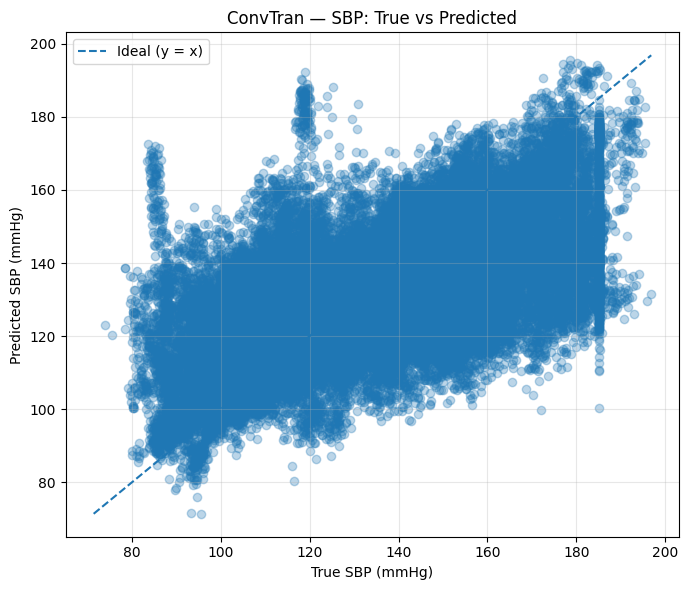

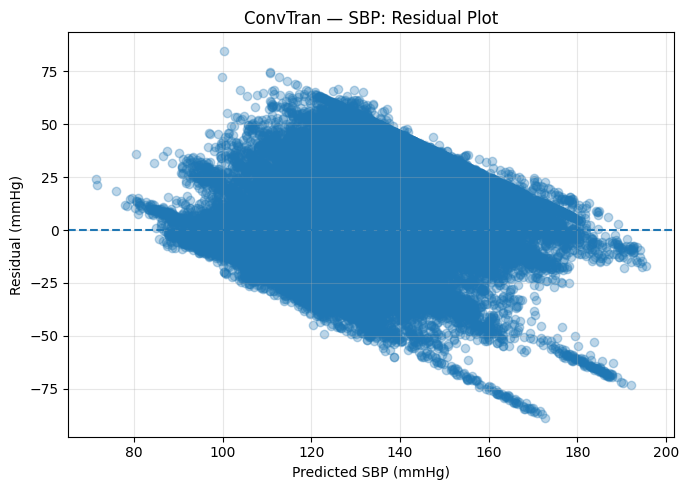

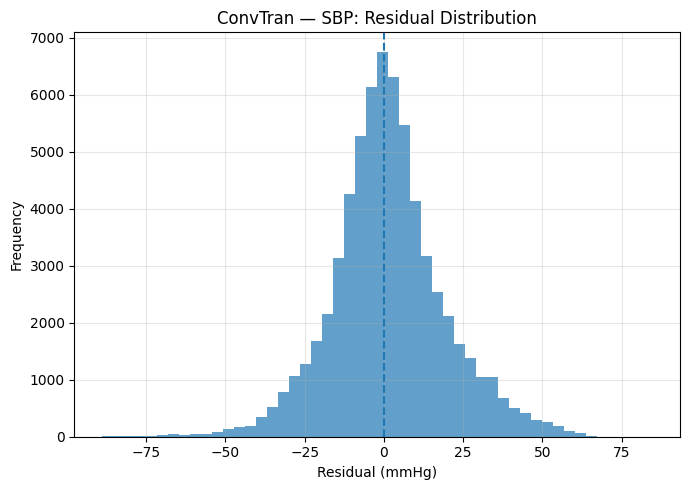

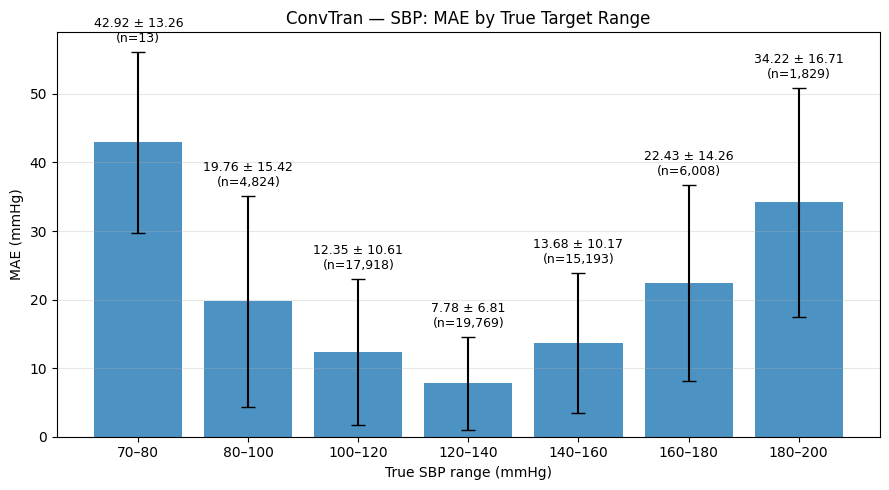

===== DBP Metrics =====
RMSE: 9.3485
MSE : 87.3951
R²  : 0.2985
MAE : 6.7876


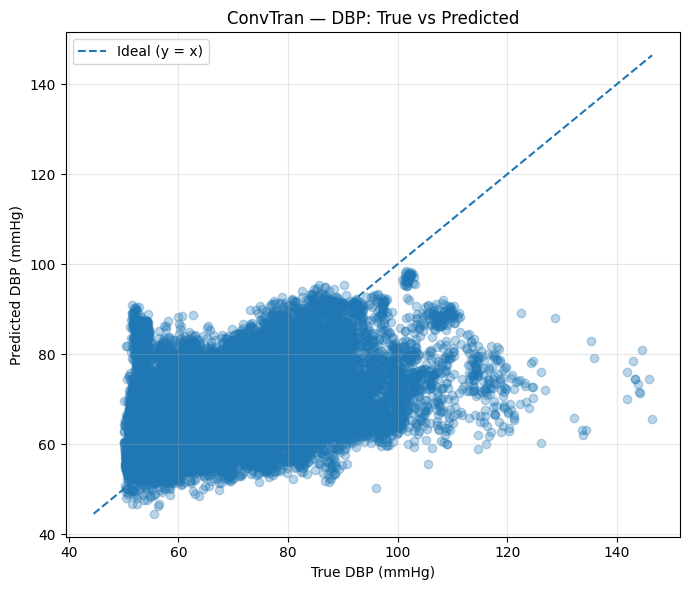

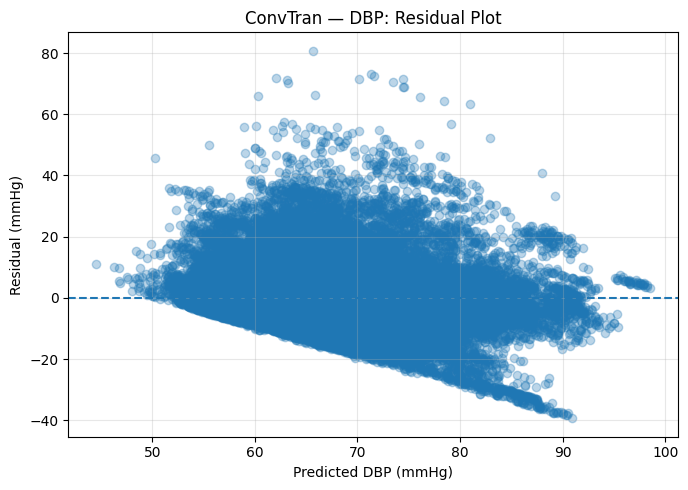

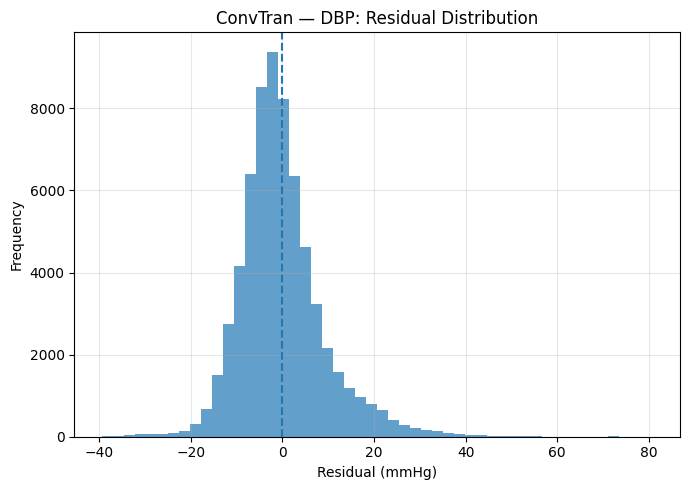

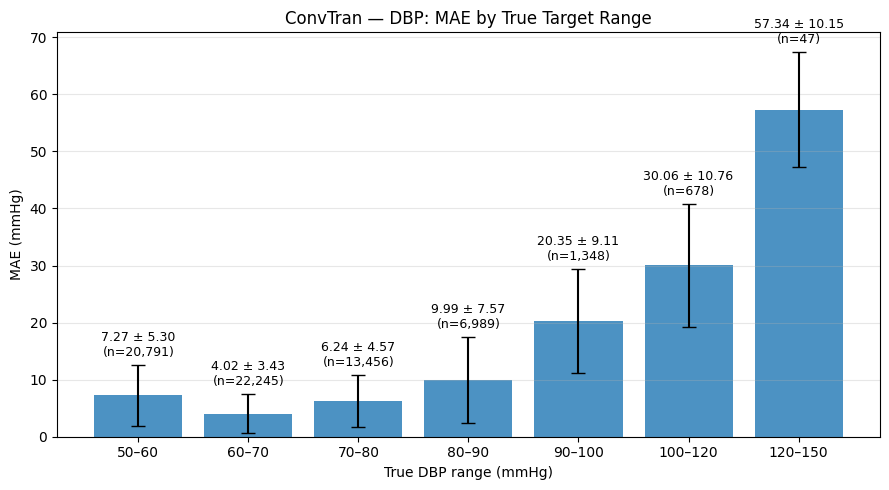

In [33]:
# Convert to NumPy arrays if they are PyTorch tensors
if torch.is_tensor(y_true):
    y_true = y_true.detach().cpu().numpy()

if torch.is_tensor(y_pred):
    y_pred = y_pred.detach().cpu().numpy()

# Extract SBP and DBP separately
sbp_true = y_true[:, 0]
sbp_pred = y_pred[:, 0]

dbp_true = y_true[:, 1]
dbp_pred = y_pred[:, 1]

# SBP metrics and plots
print("===== SBP Metrics =====")
print_metrics(sbp_true, sbp_pred)

plot_regression_results(
    sbp_true,
    sbp_pred,
    model_name="ConvTran",
    target_name="SBP"
)

# DBP metrics and plots
print("===== DBP Metrics =====")
print_metrics(dbp_true, dbp_pred)

plot_regression_results(
    dbp_true,
    dbp_pred,
    model_name="ConvTran",
    target_name="DBP"
)

Number of VitalDB cases: 1962


ConvTran VitalDB prediction: 100%|██████████| 1962/1962 [1:37:55<00:00,  2.99s/case]  



CONVTRAN
VITALDB ZERO-SHOT RESULTS

SBP
RMSE: 30.3662
MSE : 922.1068
R²  : -1.1617
MAE : 23.8845

DBP
RMSE: 16.9771
MSE : 288.2212
R²  : -0.7818
MAE : 13.5339


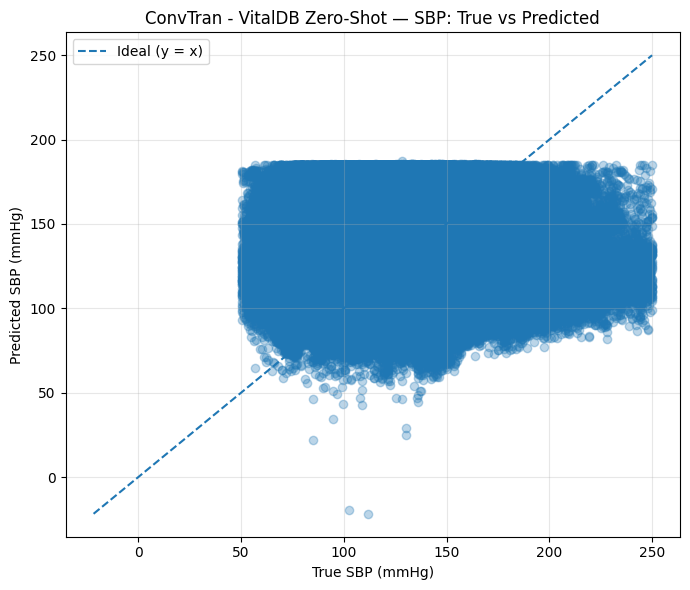

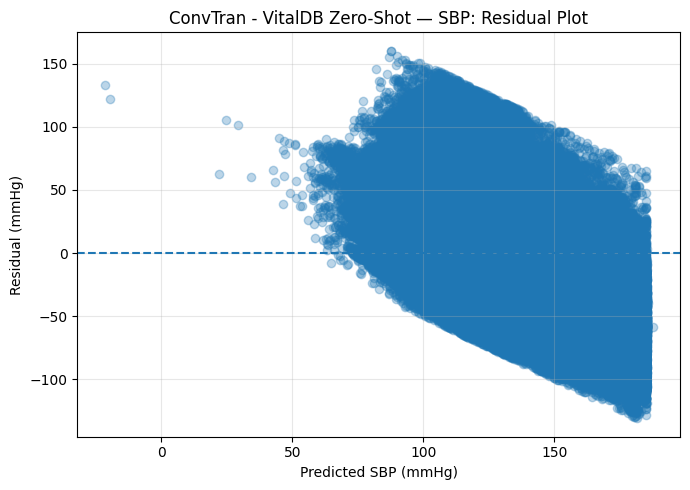

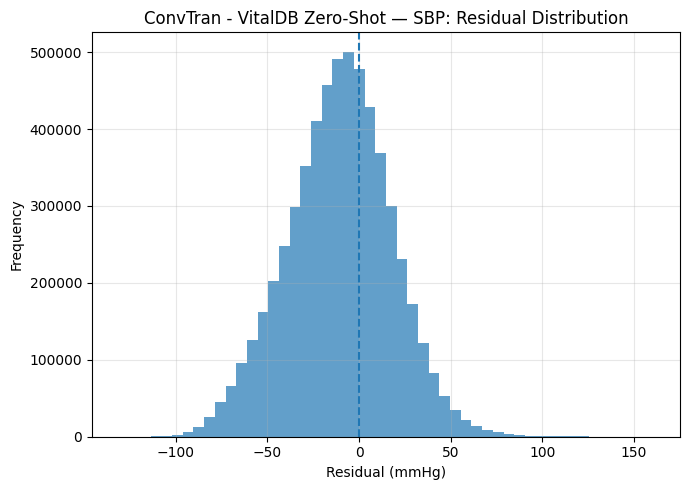

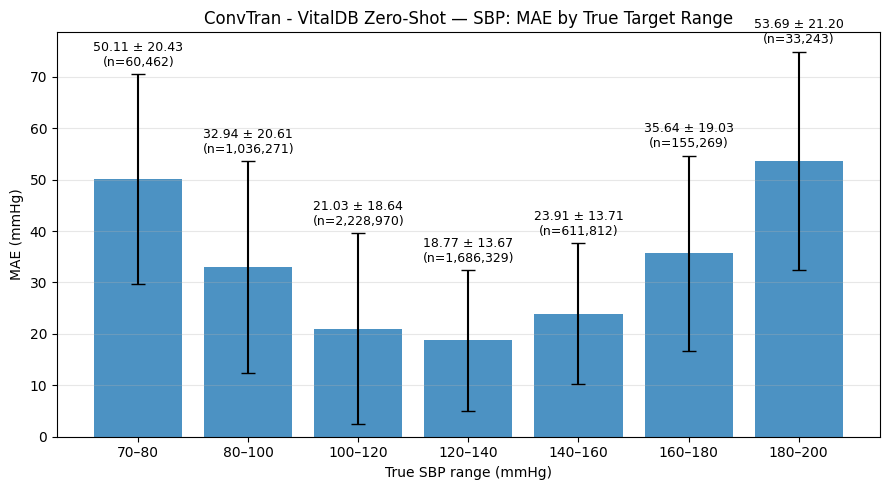

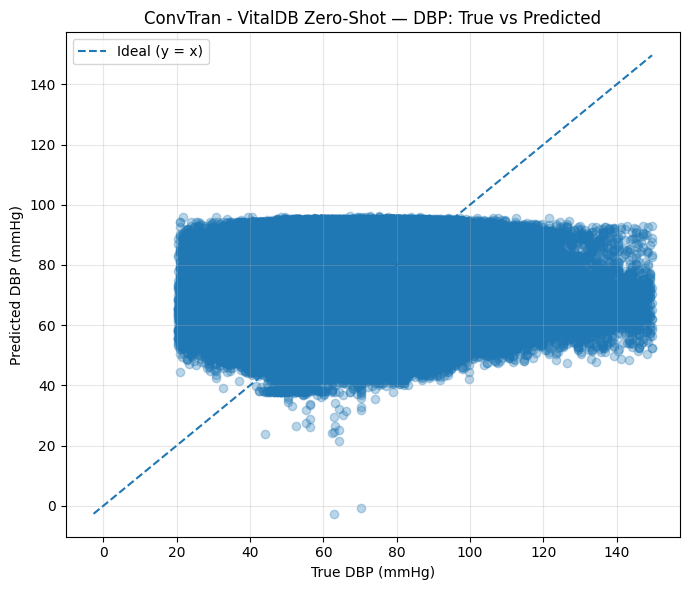

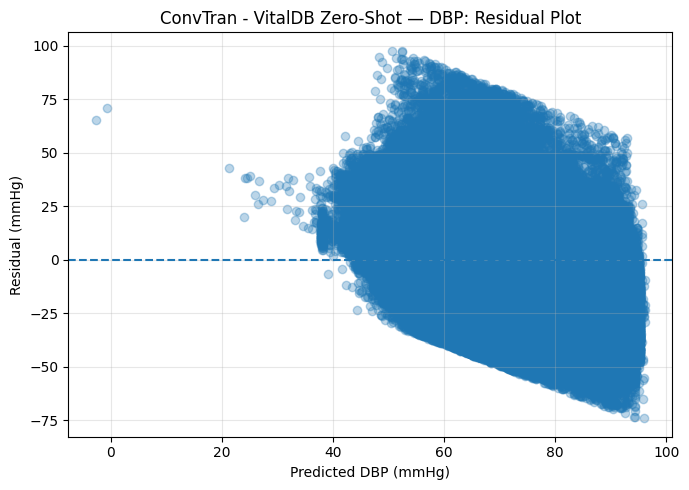

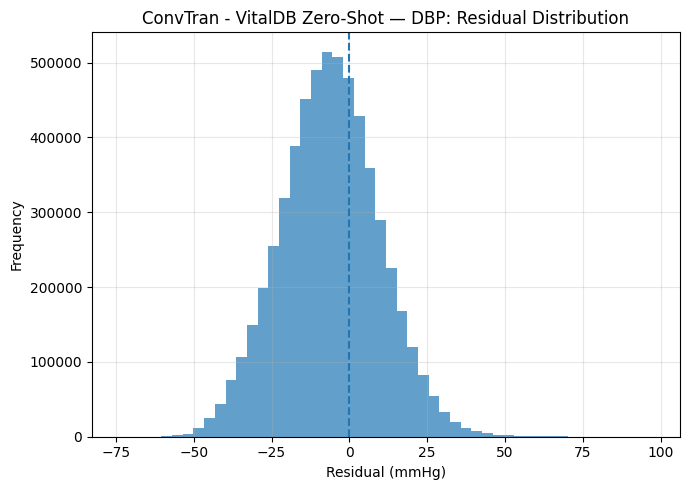

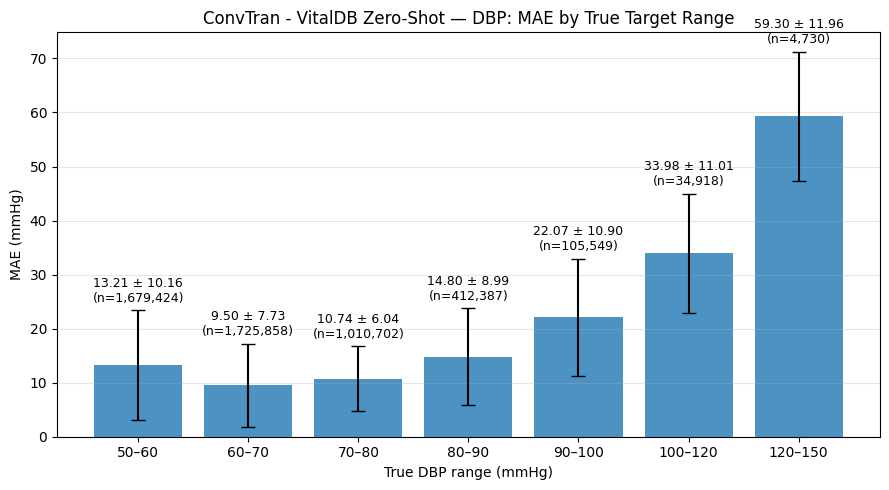

In [34]:
from processing import evaluate_convtran_vitaldb
convtran_vitaldb_results = evaluate_convtran_vitaldb(
    model=model,  # Your trained, best-checkpoint ConvTran model
    base_dir=BASE_DIR,
    batch_size=64,
    device=device
)